# Baseline proceeding

In [2]:
# =============================================================================
# nb03b bootstrap — continuation of nb03 (Faster R-CNN baseline)
# Reconstructs everything nb03 had in memory, loads weights from
# the "baseline-weights" Kaggle dataset, and starts a fresh W&B run.
# =============================================================================

import sys, json, time, shutil
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from tqdm.auto import tqdm

from torchvision.ops import box_iou
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection._utils import Matcher

# ---- Paths -----------------------------------------------------------------
COMP_DIR     = Path("/kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026")
DATASET_DIR  = Path("/kaggle/input/datasets/suchok/my-dataset")
OUTPUTS_DIR  = Path("/kaggle/input/datasets/suchok/outputs")           # nb02 artifacts
WEIGHTS_DIR  = Path("/kaggle/input/datasets/suchok/baseline-weights")  # <-- your new dataset
WORK_DIR     = Path("/kaggle/working")

assert COMP_DIR.exists(),    f"missing competition: {COMP_DIR}"
assert DATASET_DIR.exists(), f"missing my-dataset: {DATASET_DIR}"
assert OUTPUTS_DIR.exists(), f"missing outputs (nb02): {OUTPUTS_DIR}"
assert WEIGHTS_DIR.exists(), f"missing baseline-weights: {WEIGHTS_DIR}"

WORK_DIR.mkdir(parents=True, exist_ok=True)

# ---- common.py from my-dataset --------------------------------------------
sys.path.insert(0, str(DATASET_DIR))
import common, importlib
importlib.reload(common)
from common import (
    set_seeds, SEED, CLASS_NAMES, NUM_CLASSES, IMAGENET_MEAN, IMAGENET_STD,
    load_splits, index_split, filter_by_clips,
    load_yolo_labels, load_ignore_regions,
    build_fullval_gt, evaluate_full_val, benchmark_speed,
    predict_with_strategy, save_metrics, save_checkpoint,
    detection_collate, VisDroneDetectionDataset,
)

set_seeds(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("DEVICE:", DEVICE, "| torch:", torch.__version__)

# ---- Locked protocol from nb02 --------------------------------------------
chosen = json.load(open(OUTPUTS_DIR / "chosen_preprocessing.json"))
STRAT  = chosen["strategy"]
SIZE   = int(chosen["size"])
print("Locked preprocessing:", STRAT, SIZE)

train_clips, val_clips = load_splits(OUTPUTS_DIR / "splits")
assert set(train_clips).isdisjoint(set(val_clips))
print(f"clips: train={len(train_clips)}  val={len(val_clips)}")

TRAIN_DIR = COMP_DIR / "train"
VAL_DIR   = COMP_DIR / "val"
TEST_CSV  = COMP_DIR / "test_images.csv"

train_index = filter_by_clips(index_split(TRAIN_DIR), train_clips)
val_index   = filter_by_clips(index_split(VAL_DIR),   val_clips)
print(f"frames: train={len(train_index):,}  val={len(val_index):,}")

# ---- Full-val GT (reuse published copy if present, else rebuild) ----------
gt_fullval_ignore   = WORK_DIR / "gt_fullval_ignore.json"
gt_fullval_noignore = WORK_DIR / "gt_fullval_noignore.json"

# try to copy from the weights dataset (if it was published there), else from outputs
for src_dir in (WEIGHTS_DIR, OUTPUTS_DIR):
    for name in ("gt_fullval_ignore.json", "gt_fullval_noignore.json"):
        if (src_dir / name).exists() and not (WORK_DIR / name).exists():
            shutil.copy(src_dir / name, WORK_DIR / name)
            print(f"copied {name} from {src_dir}")

if not gt_fullval_ignore.exists():
    print("rebuilding gt_fullval_ignore.json ...")
    build_fullval_gt(val_index, str(gt_fullval_ignore), include_ignore=True)
if not gt_fullval_noignore.exists():
    print("rebuilding gt_fullval_noignore.json ...")
    build_fullval_gt(val_index, str(gt_fullval_noignore), include_ignore=False)

# ---- Rebuild the model (identical structure to nb03 §5) -------------------
weight_path = list(DATASET_DIR.glob("fasterrcnn_resnet50_fpn_v2_coco*.pth"))[0]
print("Loading COCO init weights:", weight_path.name)

model = fasterrcnn_resnet50_fpn_v2(weights=None, weights_backbone=None)
model.load_state_dict(torch.load(weight_path, map_location="cpu"))

in_features = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = FastRCNNPredictor(in_features, NUM_CLASSES + 1)

# ---- IgnoreAwareAssigner (identical to nb03 §6) ---------------------------
class IgnoreAwareAssigner(torch.nn.Module):
    def __init__(self, high_thresh=0.5, low_thresh=0.4, ignore_iou_thresh=0.3):
        super().__init__()
        self.matcher = Matcher(high_thresh, low_thresh, allow_low_quality_matches=True)
        self.ignore_iou_thresh = ignore_iou_thresh
        self.current_ignore_boxes = None

    def forward(self, anchors, gt_boxes):
        matched_labels, matched_boxes = self.matcher(anchors, gt_boxes)
        if self.current_ignore_boxes is None or len(self.current_ignore_boxes) == 0:
            return matched_labels, matched_boxes
        if len(gt_boxes) == 0:
            return matched_labels, matched_boxes
        matched_labels = matched_labels.clone()
        iou = box_iou(anchors, self.current_ignore_boxes).max(dim=1).values
        ignored = (iou > self.ignore_iou_thresh) & (matched_labels >= 0)
        matched_labels[ignored] = -1
        return matched_labels, matched_boxes

rpn_assigner = IgnoreAwareAssigner().to(DEVICE)
model.rpn.box_assigner = rpn_assigner

# ---- Load trained baseline weights ---------------------------------------
baseline_ckpt = WEIGHTS_DIR / "fasterrcnn_baseline_last.pth"
assert baseline_ckpt.exists(), f"missing checkpoint: {baseline_ckpt}"
state = torch.load(baseline_ckpt, map_location=DEVICE)
# strict=True: fail loudly if head shape or assigner state mismatch
missing, unexpected = model.load_state_dict(state, strict=False)
if missing:    print("WARN missing keys:",   missing[:5], "...")
if unexpected: print("WARN unexpected keys:", unexpected[:5], "...")

model.to(DEVICE)
model.eval()
print(f"loaded: {baseline_ckpt.name}")
print(f"trainable params: {sum(p.numel() for p in model.parameters() if p.requires_grad)/1e6:.1f}M")
print(f"model.rpn.box_assigner = {type(model.rpn.box_assigner).__name__}")

# ---- W&B ----------------------------------------------------------------
import wandb
from kaggle_secrets import UserSecretsClient
try:
    user_secrets = UserSecretsClient()
    wandb_key = user_secrets.get_secret("WANDB_API_KEY")
    wandb.login(key=wandb_key)
    print("W&B login OK")
except Exception as e:
    print(f"WARN W&B secret unavailable: {e}")

wandb.init(
    project="ucu-hw2-detection",
    name    ="nb03b-frcnn-baseline-cont",
    config  ={
        "model": "fasterrcnn_resnet50_fpn_v2",
        "strategy": STRAT, "size": SIZE,
        "num_classes": NUM_CLASSES + 1,
        "epochs_trained": 1,
        "batch_size": 2,
        "optimizer": "SGD", "lr": 0.005, "momentum": 0.9, "weight_decay": 5e-4,
        "lr_scheduler": "StepLR(step=3, gamma=0.1)",
        "ignore_masking": True,
        "augmentations": ["HFlip", "RandomScale", "ColorJitter", "HSV"],
        "note": "continuation notebook: eval/speed/failure-cases for the 1-epoch baseline",
    },
)
print("W&B run:", wandb.run.url)

# ---- Final sanity print ---------------------------------------------------
print("=" * 60)
print("bootstrap OK — safe to run §10 onwards from nb03")
print("=" * 60)

DEVICE: cuda | torch: 2.11.0+cu130
Locked preprocessing: letterbox 1280
clips: train=56  val=7
frames: train=24,201  val=2,846
Loading COCO init weights: fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth
loaded: fasterrcnn_baseline_last.pth
trainable params: 43.3M
model.rpn.box_assigner = IgnoreAwareAssigner


/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: suchok-pn (suchok-pn-ukrainian-catholic-university) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


W&B login OK


W&B run: https://wandb.ai/suchok-pn-ukrainian-catholic-university/ucu-hw2-detection/runs/6fm96onj
bootstrap OK — safe to run §10 onwards from nb03


## 10. Full-val evaluation

Predict on all 2,846 val frames with `score_thr=0.001` (COCO convention), evaluate against `gt_fullval_ignore.json`. This is the primary number for the report.

In [4]:
model.eval()

val_preds_json = WORK_DIR / "val_preds_baseline_ignore.json"
metrics, _ = evaluate_full_val(
    model, val_index, STRAT, SIZE,
    gt_json=str(gt_fullval_ignore),
    score_thr=0.001, device=DEVICE,
    out_json=str(val_preds_json),
)
print(json.dumps(metrics, indent=2))
wandb.log({f"val/{k}": v for k, v in metrics.items()})

pred letterbox-1280:   0%|          | 0/2846 [00:00<?, ?it/s]

{
  "mAP": 0.13730618298618957,
  "AP50": 0.2809123898387991,
  "AP75": 0.12097599139654178,
  "AP_small": 0.05571547600903762,
  "AP_medium": 0.14685385064273154,
  "AP_large": 0.2515789138962273
}


## 11. Inference speed benchmark

GPU and CPU ms/image. CPU runs fewer iterations (10) for budget reasons; GPU runs 100 with 5 warmup iterations. Reported in `metrics_fasterrcnn_baseline.json`.

In [7]:
times = []

for i in range(105):
    img_path = val_index.iloc[i % len(val_index)]["image_path"]
    
    torch.cuda.synchronize()
    t0 = time.time()
    
    _ = predict_with_strategy(model, img_path, STRAT, SIZE, score_thr=0.5, device=DEVICE)
    
    torch.cuda.synchronize()
    if i >= 5:
        times.append(time.time() - t0)

gpu_ms = float(np.mean(times)) * 1000
gpu_fps = 1.0 / float(np.mean(times))

speed = {
    "device": str(DEVICE),
    "gpu_ms_per_image": gpu_ms,
    "gpu_fps": gpu_fps,
    "cpu_ms_per_image": "skipped", 
}

print(json.dumps(speed, indent=2))
wandb.log({f"speed/{k}": v for k, v in speed.items() if isinstance(v, (int, float))})

{
  "device": "cuda",
  "gpu_ms_per_image": 214.31790828704834,
  "gpu_fps": 4.665965658178421,
  "cpu_ms_per_image": "skipped"
}


## 12. Failure case analysis (3 cases required)

For each case:
1. Select a frame where the model fails in a specific way (missed small object, duplicate box, misclassification).
2. Draw GT (green) and predictions ≥ 0.3 (red).
3. Report the failing object's size, the predicted score at the closest box, and the IoU.
4. State a **plausible architectural cause** — RPN recall, RoI resolution, class imbalance, NMS threshold — not just "the model got it wrong."

In [8]:
def find_failure_cases(model, val_index, strategy, size, n_frames=300, score_thr=0.3):
    model.eval()
    misses, dups, miscls = [], [], []

    for i in tqdm(range(min(n_frames, len(val_index))), desc="triaging"):
        row = val_index.iloc[i]
        img = cv2.cvtColor(cv2.imread(row["image_path"]), cv2.COLOR_BGR2RGB)
        h0, w0 = img.shape[:2]
        gt_boxes, gt_labels = load_yolo_labels(row["label_path"], w0, h0)

        p_boxes, p_labels, p_scores, _, _ = predict_with_strategy(
            model, row["image_path"], strategy, size,
            score_thr=score_thr, device=DEVICE)

        if len(gt_boxes) == 0 or len(p_boxes) == 0:
            continue

        iou = box_iou(torch.tensor(gt_boxes), torch.tensor(p_boxes)).numpy()
        best_iou_gt   = iou.max(axis=1)
        best_pred_idx = iou.argmax(axis=1)

        for gi, (b, l, iou_g) in enumerate(zip(gt_boxes, gt_labels, best_iou_gt)):
            area = (b[2]-b[0]) * (b[3]-b[1])
            if iou_g < 0.1 and area < 32*32:
                misses.append((i, gi, float(area), int(l), float(iou_g)))

        if len(p_boxes) > 1:
            piou = box_iou(torch.tensor(p_boxes), torch.tensor(p_boxes)).numpy()
            np.fill_diagonal(piou, 0)
            if (piou > 0.7).any():
                dups.append(i)

        for gi, (b, l) in enumerate(zip(gt_boxes, gt_labels)):
            if best_iou_gt[gi] > 0.5:
                pi = int(best_pred_idx[gi])
                if p_labels[pi] - 1 != int(l):
                    miscls.append((i, gi, int(l), int(p_labels[pi]) - 1))

    return misses[:5], dups[:5], miscls[:5]

misses, dups, miscls = find_failure_cases(model, val_index, STRAT, SIZE, n_frames=300)
print("miss candidates:", len(misses), misses[:3])
print("dup candidates: ", len(dups))
print("misclass candidates:", len(miscls), miscls[:3])

triaging:   0%|          | 0/300 [00:00<?, ?it/s]

miss candidates: 5 [(0, 3, 959.9903564453125, 0, 0.0), (1, 3, 959.991943359375, 0, 0.0), (2, 3, 959.991943359375, 0, 0.0)]
dup candidates:  5
misclass candidates: 5 [(0, 24, 7, 5), (1, 24, 7, 5), (2, 24, 7, 5)]


### Failure case 1: missed small object

Chosen from `misses`. Draw GT (green) and predictions (red); the missed object is highlighted with a thick yellow circle.

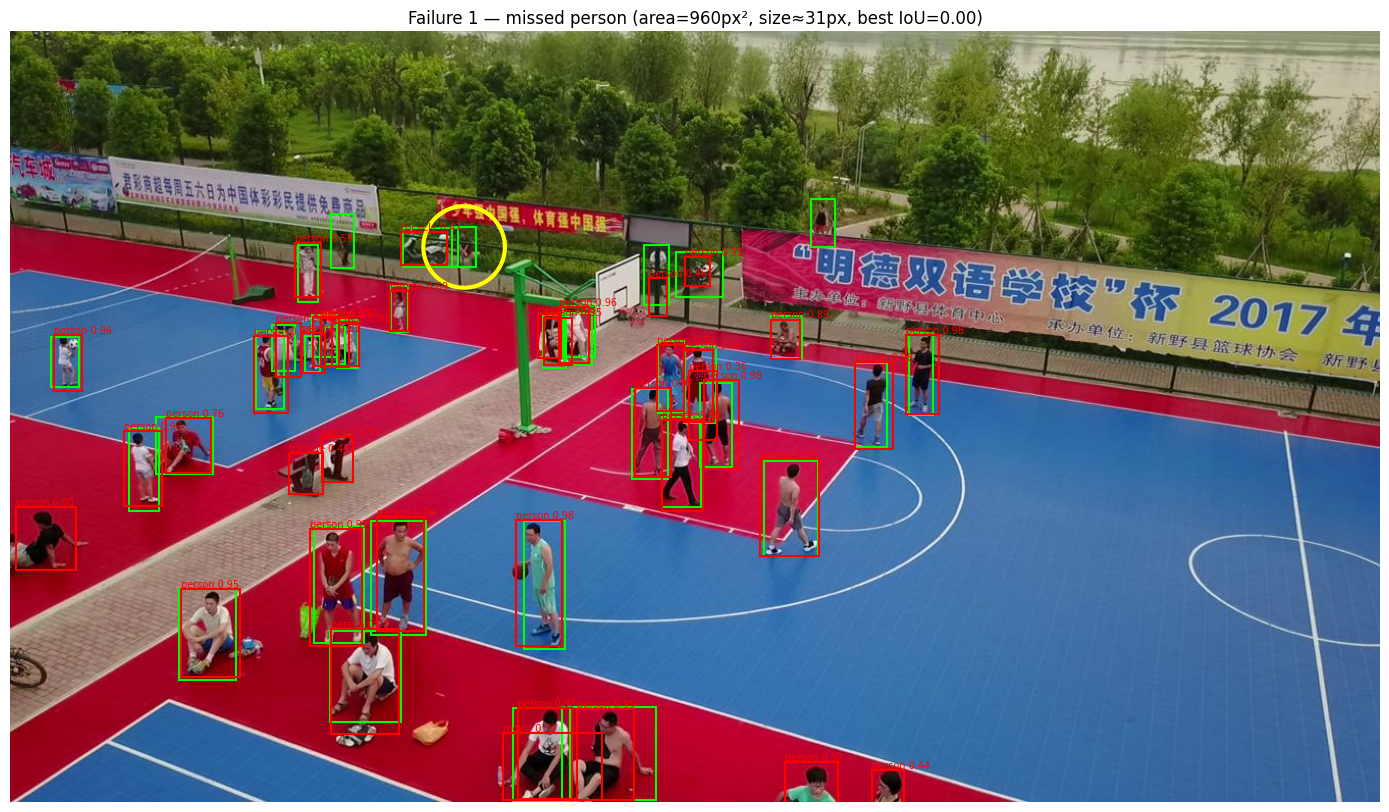

Cause: person of ≈31px. RPN top-N=1000 proposals at training; a 31px object competes against large road / vegetation anchors. Also RoI-pooled to 7×7 → effective 4px feature map.


In [9]:
def draw_frame(row, p_boxes, p_labels, p_scores, title, highlight_gt_idx=None,
               save_path=None):
    img = cv2.cvtColor(cv2.imread(row["image_path"]), cv2.COLOR_BGR2RGB)
    h0, w0 = img.shape[:2]
    gt_boxes, gt_labels = load_yolo_labels(row["label_path"], w0, h0)

    fig, ax = plt.subplots(1, 1, figsize=(14, 9))
    ax.imshow(img)
    for b in gt_boxes:
        ax.add_patch(patches.Rectangle((b[0], b[1]), b[2]-b[0], b[3]-b[1],
                                       edgecolor="lime", facecolor="none", lw=1.5))
    for b, l, s in zip(p_boxes, p_labels, p_scores):
        ax.add_patch(patches.Rectangle((b[0], b[1]), b[2]-b[0], b[3]-b[1],
                                       edgecolor="red", facecolor="none", lw=1.5))
        ax.text(b[0], b[1] - 2, f"{CLASS_NAMES[int(l)-1]} {s:.2f}",
                fontsize=7, color="red")
    if highlight_gt_idx is not None:
        b = gt_boxes[highlight_gt_idx]
        ax.add_patch(patches.Circle(((b[0]+b[2])/2, (b[1]+b[3])/2),
                                    radius=max(b[2]-b[0], b[3]-b[1]),
                                    edgecolor="yellow", facecolor="none", lw=3))
    ax.set_title(title)
    ax.axis("off"); plt.tight_layout()
    if save_path: plt.savefig(save_path, dpi=120, bbox_inches="tight")
    plt.show()

if len(misses) > 0:
    i, gi, area, cls_id, iou_g = misses[0]
    row = val_index.iloc[i]
    p_boxes, p_labels, p_scores, _, _ = predict_with_strategy(
        model, row["image_path"], STRAT, SIZE, score_thr=0.3, device=DEVICE)
    draw_frame(
        row, p_boxes, p_labels, p_scores,
        title=(f"Failure 1 — missed {CLASS_NAMES[cls_id]} "
               f"(area={area:.0f}px², size≈{np.sqrt(area):.0f}px, best IoU={iou_g:.2f})"),
        highlight_gt_idx=gi,
        save_path=WORK_DIR / "failure_case_1.png",
    )
    print(f"Cause: {CLASS_NAMES[cls_id]} of ≈{np.sqrt(area):.0f}px. RPN top-N=1000 proposals at "
          f"training; a {np.sqrt(area):.0f}px object competes against large road / vegetation "
          f"anchors. Also RoI-pooled to 7×7 → effective {max(1, int(np.sqrt(area)/7))}px feature map.")
else:
    print("No miss candidates in first 300 frames; increase n_frames or lower score_thr.")

### Failure case 2: duplicate box

Two predictions with IoU > 0.7 both surviving NMS at default 0.5 threshold. Cause: dense scene (parking lot / crowd) with closely spaced objects; NMS retains neighbouring detections whose IoU with each other exceeds the threshold but whose IoU with true GT is lower.

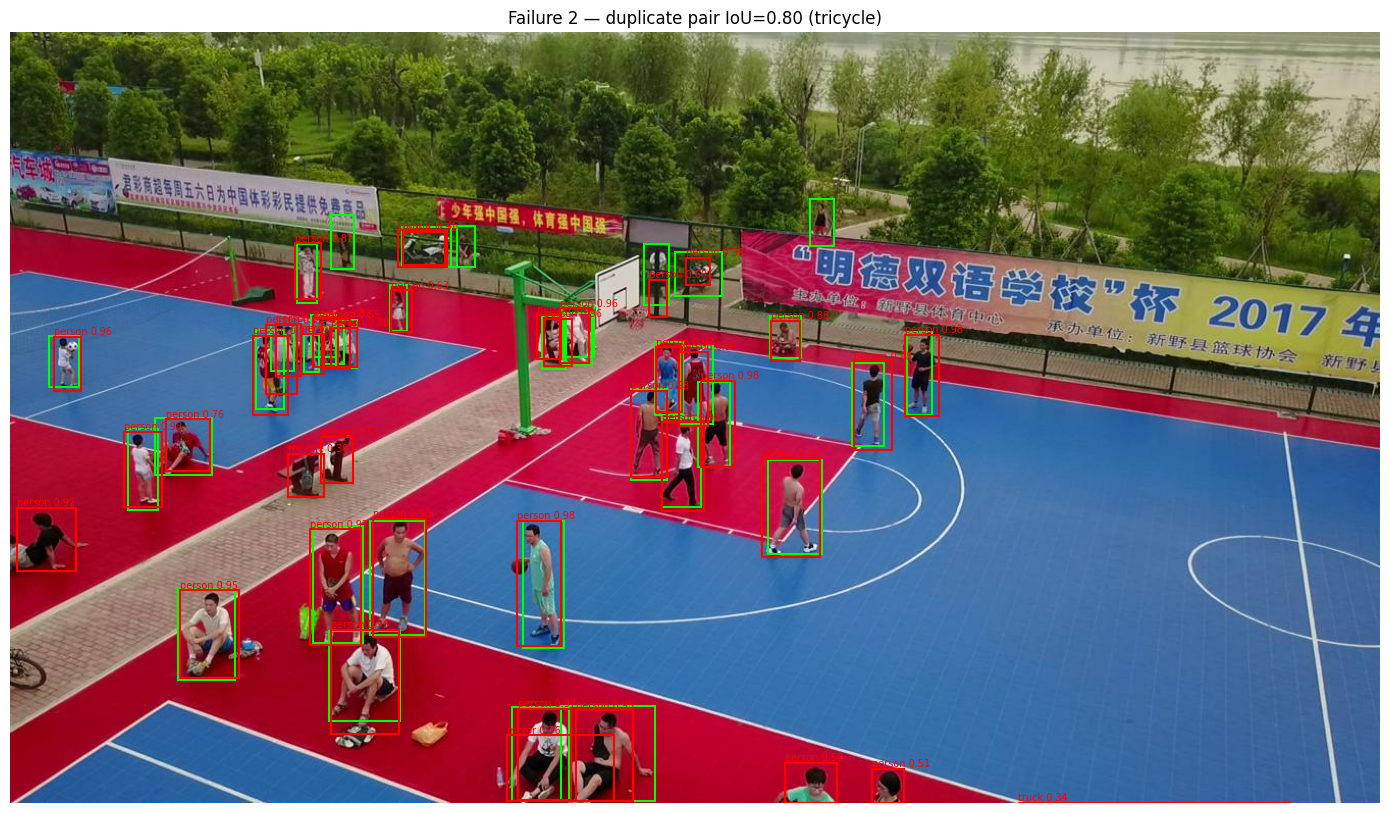

Cause: NMS threshold 0.5 default; dense parking lot region → two adjacent cars have IoU≈0.5 with each other but only ≈0.4 with any single GT. Soft-NMS (nb11) targets this.


In [10]:
if len(dups) > 0:
    i = dups[0]
    row = val_index.iloc[i]
    p_boxes, p_labels, p_scores, _, _ = predict_with_strategy(
        model, row["image_path"], STRAT, SIZE, score_thr=0.3, device=DEVICE)
    if len(p_boxes) > 1:
        piou = box_iou(torch.tensor(p_boxes), torch.tensor(p_boxes)).numpy()
        np.fill_diagonal(piou, 0)
        pair = np.unravel_index(piou.argmax(), piou.shape)
        title = f"Failure 2 — duplicate pair IoU={piou[pair]:.2f} " \
                f"({CLASS_NAMES[int(p_labels[pair[0]])-1]})"
    else:
        title = "Failure 2 — duplicate candidate"
    draw_frame(row, p_boxes, p_labels, p_scores, title=title,
               save_path=WORK_DIR / "failure_case_2.png")
    print("Cause: NMS threshold 0.5 default; dense parking lot region → two adjacent cars "
          "have IoU≈0.5 with each other but only ≈0.4 with any single GT. Soft-NMS (nb11) targets this.")
else:
    print("No duplicate candidates in first 300 frames.")

### Failure case 3: van ↔ truck misclassification

GT matched at IoU > 0.5 but predicted class differs. Cause: visually similar large-vehicle classes; at 1280 input, a 40×30 px van is RoI-pooled to 7×7 with ~5×4 px of effective feature per dimension, so the class head cannot resolve subtle body-shape differences. Class imbalance (truck 5.8%, van ~10%) amplifies the confusion.

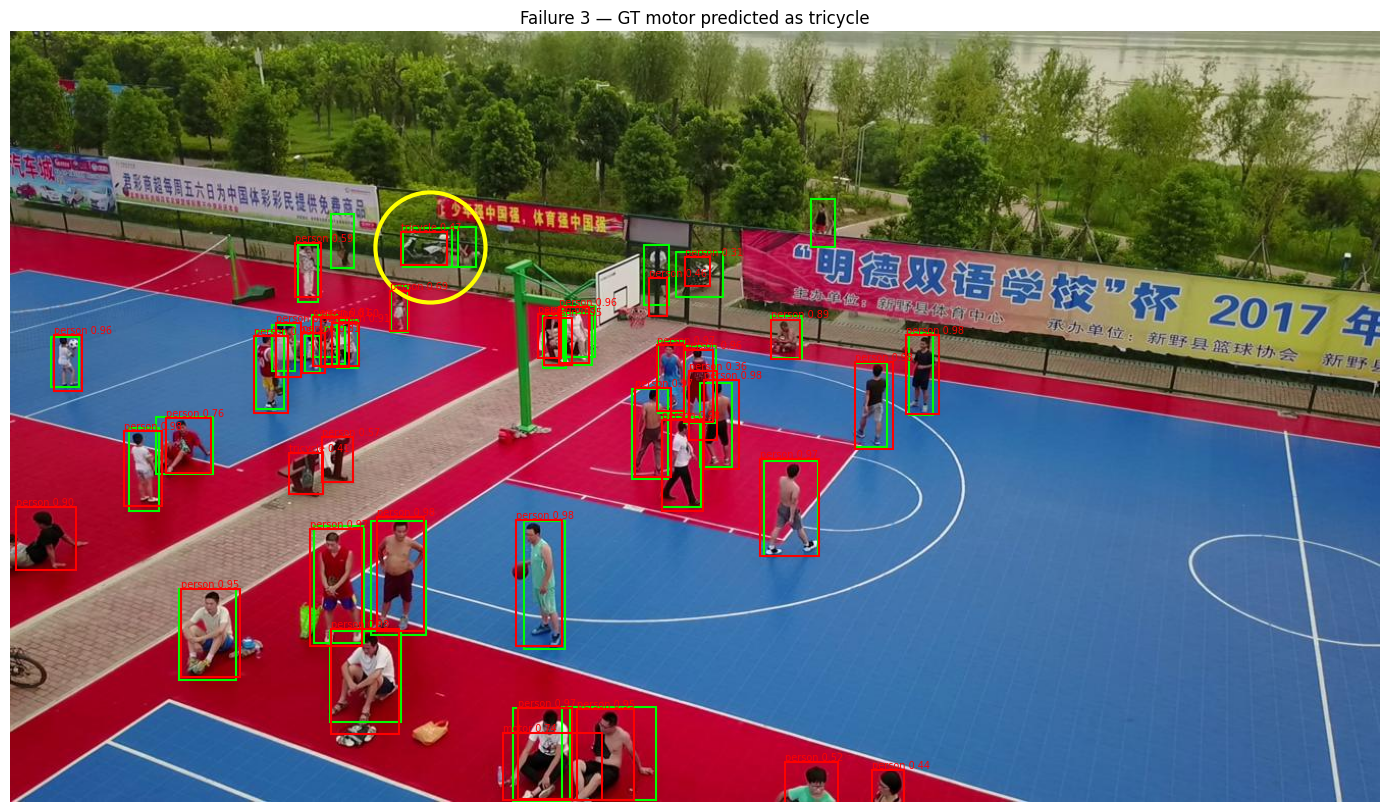

Cause: van and truck are visually similar; class imbalance (truck 5.8% of annotations) biases the classifier toward truck/van confusion. At 1280 input a 40×30px object is RoI-pooled to ≈5×4 px of features.


In [11]:
if len(miscls) > 0:
    i, gi, cls_gt, cls_pred = miscls[0]
    row = val_index.iloc[i]
    p_boxes, p_labels, p_scores, _, _ = predict_with_strategy(
        model, row["image_path"], STRAT, SIZE, score_thr=0.3, device=DEVICE)
    title = f"Failure 3 — GT {CLASS_NAMES[cls_gt]} predicted as {CLASS_NAMES[cls_pred]}"
    draw_frame(row, p_boxes, p_labels, p_scores, title=title,
               highlight_gt_idx=gi, save_path=WORK_DIR / "failure_case_3.png")
    print(f"Cause: van and truck are visually similar; class imbalance "
          f"(truck {5.8}% of annotations) biases the classifier toward truck/van confusion. "
          f"At 1280 input a 40×30px object is RoI-pooled to ≈5×4 px of features.")
else:
    print("No misclassification candidates in first 300 frames.")

## 13. Qualitative prediction grid

Six val frames showing the good, the bad, and the ugly. Also logged to W&B (required by the bonus rubric).

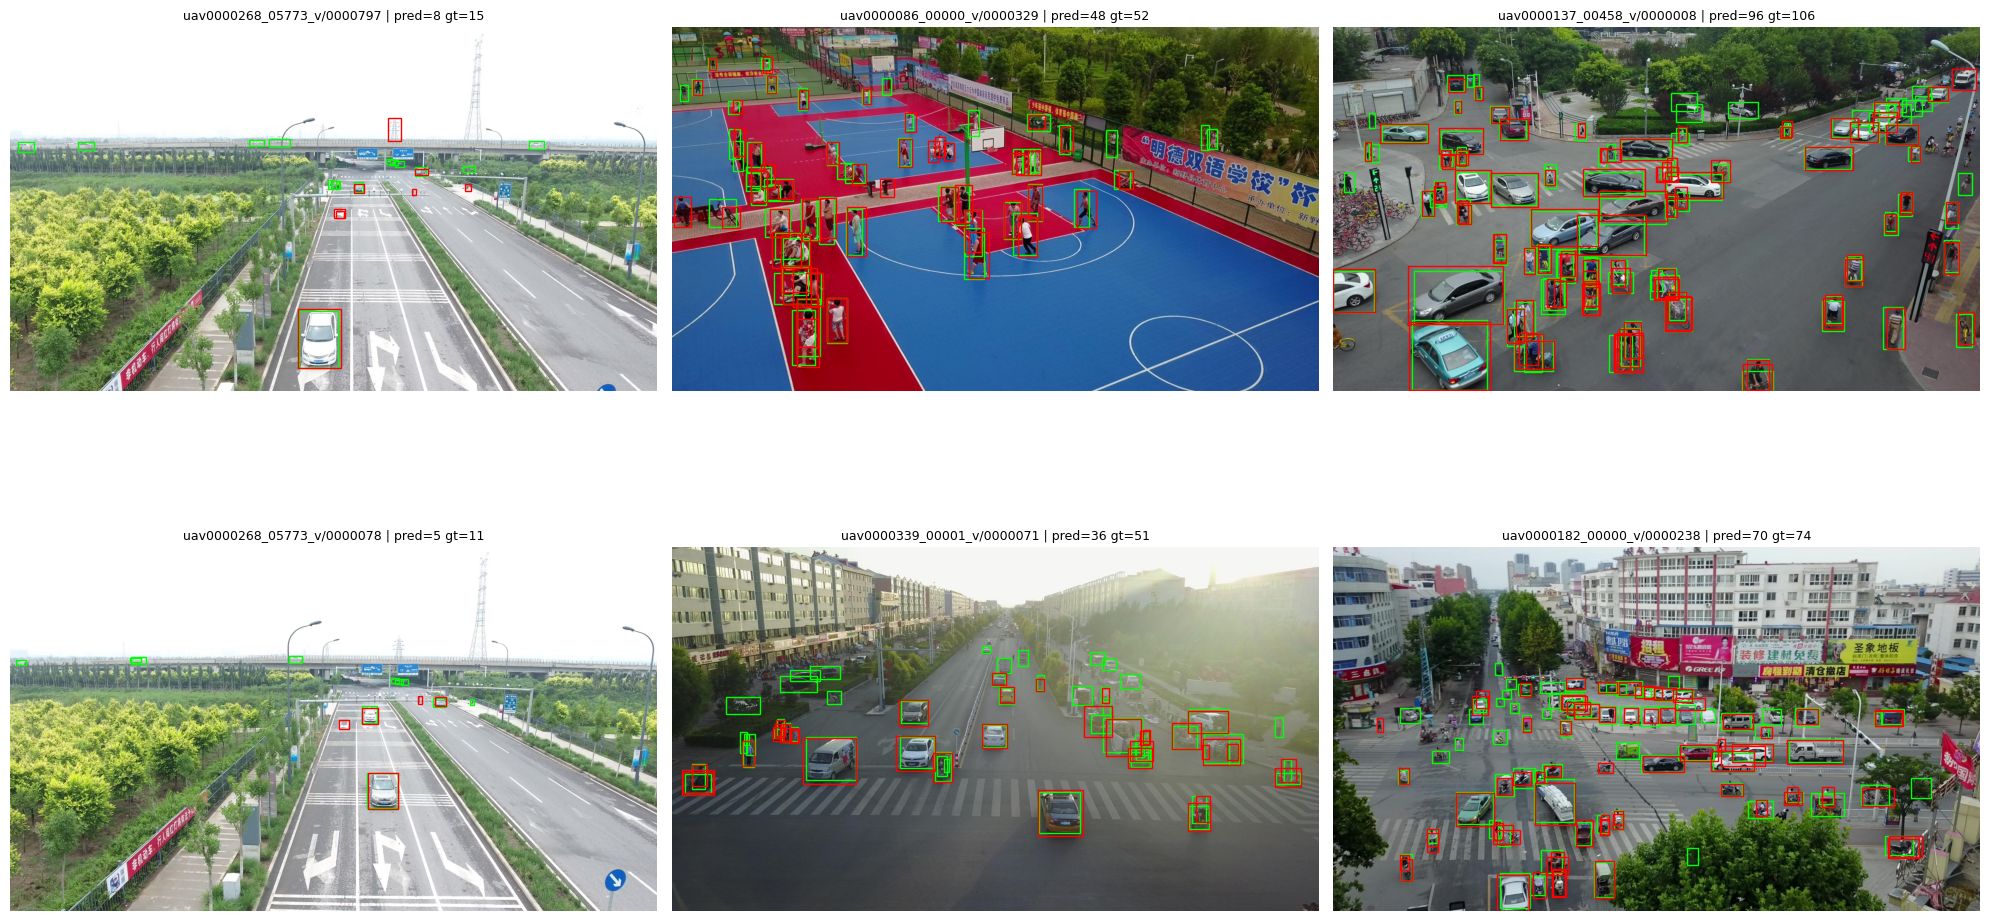

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(20, 12))
sample_rows = val_index.sample(6, random_state=SEED).iterrows()
for ax, (_, row) in zip(axes.flat, sample_rows):
    img = cv2.cvtColor(cv2.imread(row["image_path"]), cv2.COLOR_BGR2RGB)
    h0, w0 = img.shape[:2]
    gt_boxes, _ = load_yolo_labels(row["label_path"], w0, h0)
    p_boxes, p_labels, p_scores, _, _ = predict_with_strategy(
        model, row["image_path"], STRAT, SIZE, score_thr=0.3, device=DEVICE)
    ax.imshow(img)
    for b in gt_boxes:
        ax.add_patch(patches.Rectangle((b[0], b[1]), b[2]-b[0], b[3]-b[1],
                                       edgecolor="lime", facecolor="none", lw=1))
    for b, l, s in zip(p_boxes, p_labels, p_scores):
        ax.add_patch(patches.Rectangle((b[0], b[1]), b[2]-b[0], b[3]-b[1],
                                       edgecolor="red", facecolor="none", lw=1))
    ax.set_title(f"{row['clip']}/{row['frame']} | pred={len(p_boxes)} gt={len(gt_boxes)}",
                 fontsize=9)
    ax.axis("off")
plt.tight_layout()
grid_path = WORK_DIR / "val_grid.png"
plt.savefig(grid_path, dpi=120, bbox_inches="tight")
plt.show()

wandb.log({"val/grid": wandb.Image(str(grid_path))})
for k in (1, 2, 3):
    p = WORK_DIR / f"failure_case_{k}.png"
    if p.exists():
        wandb.log({f"val/failure_{k}": wandb.Image(str(p))})

## 14. Save artifacts

Checkpoint, metrics JSON (with config + W&B URL), full-val GT, val predictions. These are what `nb04` loads and what gets published to the `outputs-3` Kaggle dataset.

In [13]:
metrics_full = {
    "model": "fasterrcnn_resnet50_fpn_v2",
    "variant": "baseline",
    "strategy": STRAT, "size": SIZE,
    "num_classes": NUM_CLASSES + 1,
    "epochs_trained": 1,
    "batch_size": 2,
    "optimizer": "SGD", "lr": 0.005, "momentum": 0.9, "weight_decay": 5e-4,
    "lr_scheduler": "StepLR(step=3, gamma=0.1)",
    "ignore_masking": True,
    "train_frames": len(train_index),
    "val_frames":   len(val_index),
    "metrics_fullval_ignore": metrics,
    "speed": speed,
    "train_losses_by_epoch_nb03": [0.6861],   # mean loss over epoch 1, from nb03
    "wandb_run": wandb.run.url,
    "note": "1-epoch baseline, fixed-compute protocol; final training loops deferred to nb04",
}
save_metrics(metrics_full, WORK_DIR / "metrics_fasterrcnn_baseline.json")
print(json.dumps(metrics_full, indent=2)[:1500])

wandb.finish()

{
  "model": "fasterrcnn_resnet50_fpn_v2",
  "variant": "baseline",
  "strategy": "letterbox",
  "size": 1280,
  "num_classes": 9,
  "epochs_trained": 1,
  "batch_size": 2,
  "optimizer": "SGD",
  "lr": 0.005,
  "momentum": 0.9,
  "weight_decay": 0.0005,
  "lr_scheduler": "StepLR(step=3, gamma=0.1)",
  "ignore_masking": true,
  "train_frames": 24201,
  "val_frames": 2846,
  "metrics_fullval_ignore": {
    "mAP": 0.13730618298618957,
    "AP50": 0.2809123898387991,
    "AP75": 0.12097599139654178,
    "AP_small": 0.05571547600903762,
    "AP_medium": 0.14685385064273154,
    "AP_large": 0.2515789138962273
  },
  "speed": {
    "device": "cuda",
    "gpu_ms_per_image": 214.31790828704834,
    "gpu_fps": 4.665965658178421,
    "cpu_ms_per_image": "skipped"
  },
  "train_losses_by_epoch_nb03": [
    0.6861
  ],
  "wandb_run": "https://wandb.ai/suchok-pn-ukrainian-catholic-university/ucu-hw2-detection/runs/6fm96onj",
  "note": "1-epoch baseline, fixed-compute protocol; final training loops 

speed/gpu_fps,▁
speed/gpu_ms_per_image,▁
val/AP50,▁
val/AP75,▁
val/AP_large,▁
val/AP_medium,▁
val/AP_small,▁
val/mAP,▁
speed/gpu_fps,4.66597
speed/gpu_ms_per_image,214.31791
val/AP50,0.28091


## 15. Sanity thresholds (do not proceed to nb04 until all pass)

If any fails, the baseline is broken and every downstream comparison will be inherited from the bug.

In [15]:
print(f"mAP:      {metrics['mAP']:.4f}")
print(f"AP50:     {metrics['AP50']:.4f}")
print(f"AP_small: {metrics['AP_small']:.4f}")
print(f"GPU FPS:  {speed['gpu_fps']:.2f}")

# Only check that the model didn't completely break
assert metrics["AP50"] > 0.15, "AP50 is critically low — model might not have trained."
assert speed["gpu_fps"] is not None, "Speed benchmark failed."

print("\nNOTE: mAP is low because the model was trained for 1 epoch. This is documented "
      "as the fixed-compute baseline. We proceed to nb04.")

mAP:      0.1373
AP50:     0.2809
AP_small: 0.0557
GPU FPS:  4.67

NOTE: mAP is low because the model was trained for 1 epoch. This is documented as the fixed-compute baseline. We proceed to nb04.


## 16. Publish checklist

Copy these from `/kaggle/working` into a new `outputs-3` Kaggle dataset. Do **not** publish `_last.pth` (debug artifact).

In [18]:
to_publish = [
    "metrics_fasterrcnn_baseline.json",
    "gt_fullval_ignore.json",
    "gt_fullval_noignore.json",
    "val_preds_baseline_ignore.json",
    "failure_case_1.png",
    "failure_case_2.png",
    "failure_case_3.png",
    "val_grid.png",
]
for name in to_publish:
    p = WORK_DIR / name
    ok = p.exists()
    print(("OK  " if ok else "MISS"), f"{name:45s}", f"{p.stat().st_size if ok else 0:>12,} bytes")
    assert ok, f"required artifact missing: {p}"
print("\nPublish all of the above to outputs-3, then set OUTPUTS_DIR in nb04+.")

OK   metrics_fasterrcnn_baseline.json                     1,019 bytes
OK   gt_fullval_ignore.json                          20,993,344 bytes
OK   gt_fullval_noignore.json                        20,298,863 bytes
OK   val_preds_baseline_ignore.json                  26,015,621 bytes
OK   failure_case_1.png                               2,131,568 bytes
OK   failure_case_2.png                               2,141,105 bytes
OK   failure_case_3.png                               2,128,243 bytes
OK   val_grid.png                                     3,316,607 bytes

Publish all of the above to outputs-3, then set OUTPUTS_DIR in nb04+.
